## 0. Setup and specifications

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score

RANDOM_STATE = 42
DATA_PATH = "data/raw_milk_reception.csv"

# ---- ILLUSTRATIVE limits: replace with your national standard / company specification ----
SPEC = dict(temp_max=8.0,          # arrival temperature, C
            tbc_max=500.0,         # total bacterial count, thousand CFU/mL
            scc_max=750.0,         # somatic cell count, thousand cells/mL
            acidity_max=19.0,      # titratable acidity, Dornic degrees (1 degD ~ 0.1 g lactic acid / L)
            fp_max=-0.505)         # freezing point, C: warmer than this suggests added water
FP_REF = -0.520                    # typical freezing point of genuine milk (use your own regional baseline)

TEAL, RED, AMBER, GREY, GREEN = "#1F7A8C", "#C0392B", "#E0A028", "#6B7280", "#2F7D4F"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.4


## 1. Load and audit the raw export

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (2631, 17)


,Sample_ID,Date,Center,Volume_L,Temp_Arrival_C,Alcohol_Test,Antibiotic_Test,Fat_pct,Protein_pct,SNF_pct,Density_g_ml,Freezing_Point_C,Acidity_Dornic,pH,SCC_k,TBC_k,Confirmed_Adulterant
0,MK51615,2024-04-07,Center-08,5000.0,2.2,Negative,Negative,3.75,3.22,8.76,1.0315,-0.52,16.4,6.71,65.0,72.0,NaN
1,MK50568,2023-06-14,Center-08,8000.0,7.2,Negative,Negative,3.41,3.07,8.59,1.0311,-0.516,13.7,6.74,178.0,137.0,NaN
2,MK50444,2023-05-07,Center-06,5000.0,5.8,Negative,Negative,3.74,3.17,8.66,1.0311,-0.522,15.6,6.74,175.0,245.0,NaN
3,MK50878,2023-09-05,Center-07,8000.0,8.2,Negative,Negative,3.29,3.01,8.56,1.0310,-0.52,16.0,6.75,228.0,125.0,NaN
4,MK50086,2023-01-21,Center-02,3000.0,5.4,Negative,Negative,3.4,3.26,8.73,1.0316,-0.523,14.7,6.74,391.0,29.0,NaN


In [3]:
NUM_COLS = ["Volume_L", "Temp_Arrival_C", "Fat_pct", "Protein_pct", "SNF_pct", "Density_g_ml",
            "Freezing_Point_C", "Acidity_Dornic", "pH", "SCC_k", "TBC_k"]

def non_numeric_values(s):
    converted = pd.to_numeric(s, errors="coerce")
    return s[converted.isna() & s.notna()]

print("Numeric columns that contain text:")
for col in NUM_COLS:
    bad = non_numeric_values(raw[col])
    if len(bad):
        print(f"  {col:17s} {len(bad):3d} entries, e.g. {[str(v) for v in bad.unique()[:3]]}")

iso = pd.to_datetime(raw["Date"], format="%Y-%m-%d", errors="coerce")
print("\nDates not in ISO format:", int((iso.isna() & raw["Date"].notna()).sum()))
print("Centre spellings:", raw["Center"].nunique(), "(should be 12)")
print("Alcohol-test spellings:", sorted(raw["Alcohol_Test"].dropna().unique().tolist()))
print("Repeated Sample_IDs:", int(raw["Sample_ID"].duplicated().sum()))
print("Temperatures above 25 (not plausible in C):", int((pd.to_numeric(raw["Temp_Arrival_C"], errors="coerce") > 25).sum()))
fp_num = pd.to_numeric(raw["Freezing_Point_C"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("Freezing points above 0 (lost minus sign?):", int((fp_num > 0).sum()))
print("\nConfirmed_Adulterant filled for", int(raw["Confirmed_Adulterant"].notna().sum()), "of", len(raw), "samples")
pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(1)})

Numeric columns that contain text:
  Fat_pct            24 entries, e.g. ['3,33', '3,75', '3,37']
  Protein_pct        25 entries, e.g. ['3,1', '3,34', '3,33']
  Freezing_Point_C   24 entries, e.g. ['-0,522', '-0,521', '-0,519']
  pH                 26 entries, e.g. ['6,72', '6,73', '6,74']

Dates not in ISO format: 40
Centre spellings: 44 (should be 12)
Alcohol-test spellings: ['NEG ', 'Negative', 'Negative ', 'POS ', 'Positive', 'neg', 'pos']
Repeated Sample_IDs: 30
Temperatures above 25 (not plausible in C): 31
Freezing points above 0 (lost minus sign?): 20

Confirmed_Adulterant filled for 275 of 2631 samples


,dtype,missing,missing_%
Sample_ID,str,0,0.0
Date,str,1,0.0
Center,str,1,0.0
Volume_L,float64,1,0.0
Temp_Arrival_C,float64,22,0.8
Alcohol_Test,str,1,0.0
Antibiotic_Test,str,1,0.0
Fat_pct,str,21,0.8
Protein_pct,str,20,0.8
SNF_pct,float64,23,0.9


### Audit findings
* footer row, **duplicate samples**, **mixed date formats**, **decimal commas**,
* centre names written several ways, test results in several spellings,
* **temperatures typed in °F** and **freezing points without the minus sign** (a classic lab-entry error),
* impossible values (pH 67, fat 355), missing values,
* confirmatory adulteration results exist for only a **small subset** — this matters later.

## 2. Cleaning

Domain rules drive the repairs: a chilled raw-milk tanker cannot be above 25 °C (a value of 38 is 38 °F ≈ 3 °C), and the freezing point of milk is always negative (a positive value between 0.45 and 0.60 is a lost minus sign).

In [4]:
log = [("raw export", len(raw))]
df = raw.copy()

# 1) footer / non-sample rows
is_sample = df["Sample_ID"].astype(str).str.match(r"^MK\d+$")
print("Non-sample rows removed:", int((~is_sample).sum()))
df = df[is_sample].copy()
log.append(("remove footer rows", len(df)))

# 2) duplicate samples
dups = df["Sample_ID"].duplicated(keep=False)
print(f"Rows sharing a Sample_ID: {int(dups.sum())} (exact copies: {int(df[dups].duplicated(keep=False).sum())})")
df = df.drop_duplicates(subset="Sample_ID", keep="first").copy()
log.append(("drop duplicate samples", len(df)))

# 3) dates
d_iso = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
d_alt = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")
df["Date"] = d_iso.fillna(d_alt)
print("Dates not parsed:", int(df["Date"].isna().sum()))

# 4) categorical spelling
num = df["Center"].astype(str).str.extract(r"(\d+)")[0].astype(int)
df["Center"] = "Center-" + num.astype(str).str.zfill(2)
for col in ["Alcohol_Test", "Antibiotic_Test"]:
    s = df[col].astype(str).str.strip().str.lower()
    df[col] = np.where(s.str.startswith("pos"), "Positive", np.where(s.str.startswith("neg"), "Negative", None))
print("Centres:", df["Center"].nunique(), "| Alcohol:", df["Alcohol_Test"].value_counts().to_dict())

Non-sample rows removed: 1
Rows sharing a Sample_ID: 60 (exact copies: 60)
Dates not parsed: 0
Centres: 12 | Alcohol: {'Negative': 2550, 'Positive': 50}


In [5]:
# 5) numeric repair (decimal commas)
comma_fixed = {}
for col in NUM_COLS:
    as_text = df[col].astype(str).str.strip()
    comma_fixed[col] = int(as_text.str.contains(",", regex=False).sum())
    df[col] = pd.to_numeric(as_text.str.replace(",", ".", regex=False), errors="coerce")
print("Decimal commas repaired:", {k: v for k, v in comma_fixed.items() if v})

# 6) unit and sign errors found in the audit
f_mask = df["Temp_Arrival_C"] > 25
df.loc[f_mask, "Temp_Arrival_C"] = ((df.loc[f_mask, "Temp_Arrival_C"] - 32) * 5 / 9).round(1)
print("Temperatures converted from F to C:", int(f_mask.sum()))

neg_fix = df["Freezing_Point_C"].between(0.45, 0.60)
df.loc[neg_fix, "Freezing_Point_C"] = -df.loc[neg_fix, "Freezing_Point_C"]
print("Freezing points with restored minus sign:", int(neg_fix.sum()))

# 7) physically impossible values -> NaN
RANGES = {"Volume_L": (500, 40000), "Temp_Arrival_C": (-5, 25), "Fat_pct": (0.5, 10), "Protein_pct": (1, 8),
          "SNF_pct": (5, 12), "Density_g_ml": (1.020, 1.040), "Freezing_Point_C": (-0.65, -0.30),
          "Acidity_Dornic": (5, 30), "pH": (5, 8), "SCC_k": (0, 5000), "TBC_k": (0, 100000)}
removed = {}
for col, (lo, hi) in RANGES.items():
    invalid = df[col].notna() & ~df[col].between(lo, hi)
    removed[col] = int(invalid.sum())
    df.loc[invalid, col] = np.nan
print("Impossible values set to missing:", {k: v for k, v in removed.items() if v})

Decimal commas repaired: {'Fat_pct': 24, 'Protein_pct': 25, 'Freezing_Point_C': 24, 'pH': 25}
Temperatures converted from F to C: 30
Freezing points with restored minus sign: 20
Impossible values set to missing: {'Fat_pct': 5, 'pH': 4}


In [6]:
df = df.sort_values(["Date", "Sample_ID"]).reset_index(drop=True)
log.append(("final (types, units and ranges repaired)", len(df)))
miss = df[NUM_COLS].isna().sum()
print("Remaining missing values:", miss[miss > 0].to_dict())
summary = pd.DataFrame(log, columns=["cleaning step", "rows"])
summary["removed"] = (-summary["rows"].diff()).fillna(0).astype(int)
summary

Remaining missing values: {'Temp_Arrival_C': 21, 'Fat_pct': 25, 'Protein_pct': 18, 'SNF_pct': 22, 'Density_g_ml': 18, 'Freezing_Point_C': 14, 'Acidity_Dornic': 19, 'pH': 31, 'SCC_k': 19, 'TBC_k': 21}


,cleaning step,rows,removed
0,raw export,2631,0
1,remove footer rows,2630,1
2,drop duplicate samples,2600,30
3,"final (types, units and ranges repaired)",2600,0


## 3. Are the composition results physically consistent?

Fat, density and solids-not-fat (SNF) are linked. A Richmond-type formula estimates SNF from the corrected lactometer reading (CLR = (density − 1) × 1000) and fat:

**SNF ≈ CLR / 4 + 0.2 × fat + 0.14**

Large gaps between measured and expected SNF point to an instrument problem or a key-entry error — and are worth re-testing before anyone acts on the result.

Complete rows checked: 2535 | median |gap| = 0.01 | flagged (|gap| > 0.4): 15


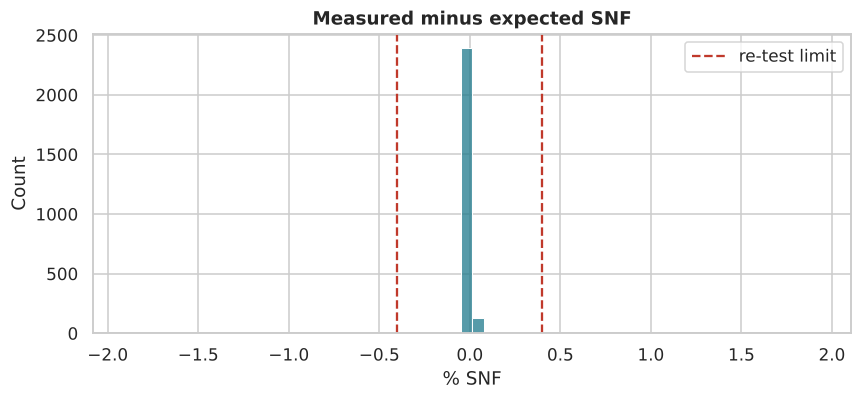

In [7]:
clr = (df["Density_g_ml"] - 1) * 1000
df["SNF_expected"] = clr / 4 + 0.2 * df["Fat_pct"] + 0.14
df["SNF_gap"] = df["SNF_pct"] - df["SNF_expected"]
df["snf_inconsistent"] = df["SNF_gap"].abs() > 0.4

print(f"Complete rows checked: {int(df['SNF_gap'].notna().sum())} | median |gap| = {df['SNF_gap'].abs().median():.2f} "
      f"| flagged (|gap| > 0.4): {int(df['snf_inconsistent'].sum())}")

plt.figure(figsize=(8, 3.8))
sns.histplot(df["SNF_gap"].dropna(), bins=60, color=TEAL)
plt.axvline(0.4, color=RED, ls="--"); plt.axvline(-0.4, color=RED, ls="--", label="re-test limit")
plt.title("Measured minus expected SNF"); plt.xlabel("% SNF"); plt.legend()
plt.tight_layout()

## 4. Exploring quality: seasonality and collection centres

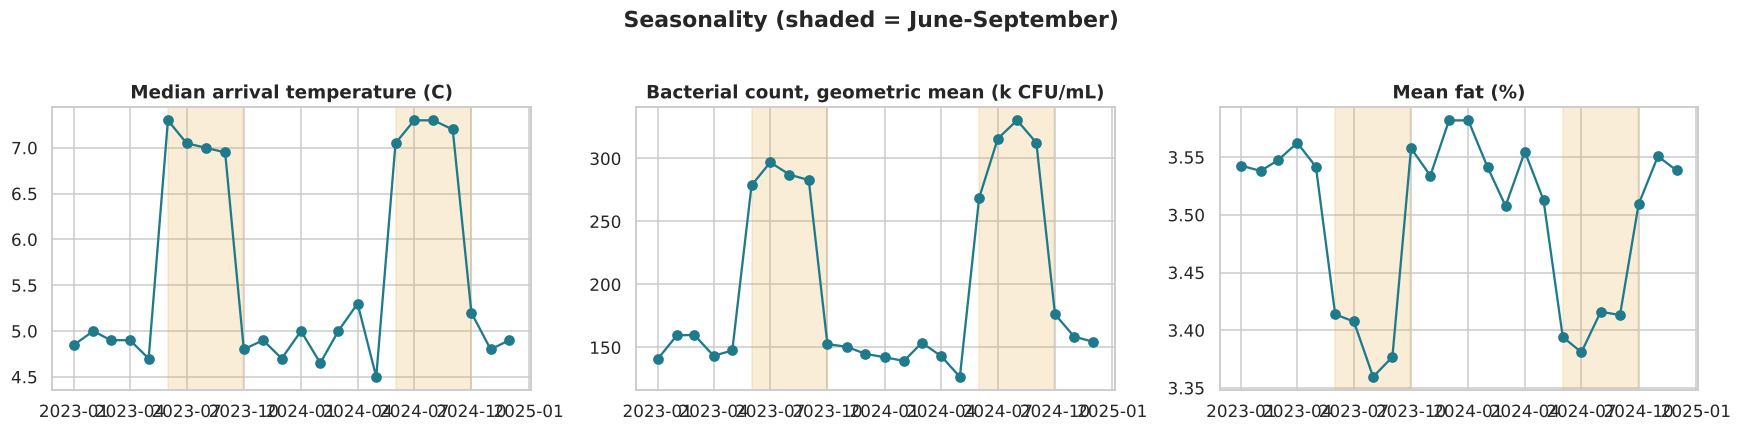

In [8]:
df["Month"] = df["Date"].dt.to_period("M")

def gmean(s):
    s = s.dropna(); s = s[s > 0]
    return float(np.exp(np.log(s).mean()))

monthly = df.groupby("Month").agg(temp=("Temp_Arrival_C", "median"), fat=("Fat_pct", "mean"))
monthly["tbc_gm"] = df.groupby("Month")["TBC_k"].apply(gmean)
x = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["temp", "tbc_gm", "fat"],
                          ["Median arrival temperature (C)", "Bacterial count, geometric mean (k CFU/mL)", "Mean fat (%)"]):
    ax.plot(x, monthly[col], marker="o", color=TEAL)
    for yr in (2023, 2024):
        ax.axvspan(pd.Timestamp(f"{yr}-06-01"), pd.Timestamp(f"{yr}-09-30"), color=AMBER, alpha=0.18)
    ax.set_title(title)
plt.suptitle("Seasonality (shaded = June-September)", fontweight="bold", y=1.03)
plt.tight_layout()

Kruskal-Wallis, TBC across centres: H = 454, p = 2.3e-90
Worst two centres (median log10 TBC): ['Center-03', 'Center-09']


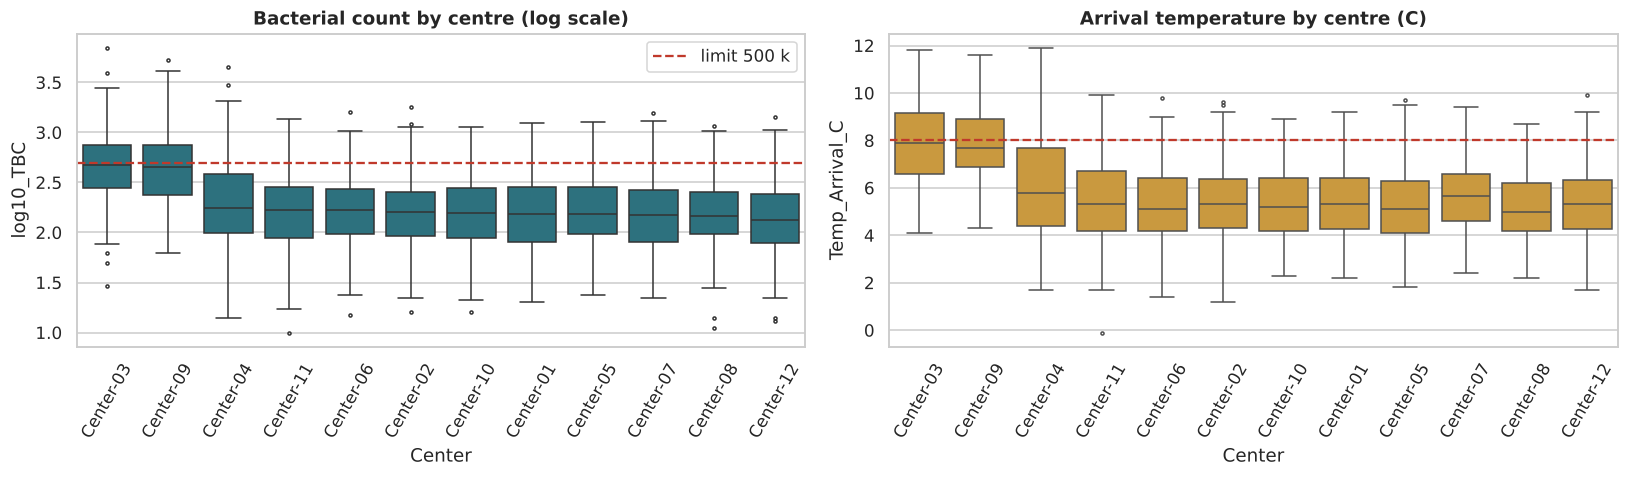

In [9]:
df["log10_TBC"] = np.log10(df["TBC_k"].clip(lower=1))
order = df.groupby("Center")["log10_TBC"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df, x="Center", y="log10_TBC", order=order, color=TEAL, fliersize=2, ax=axes[0])
axes[0].axhline(np.log10(SPEC["tbc_max"]), color=RED, ls="--", label=f"limit {SPEC['tbc_max']:.0f} k")
axes[0].set_title("Bacterial count by centre (log scale)"); axes[0].tick_params(axis="x", rotation=60); axes[0].legend()
sns.boxplot(data=df, x="Center", y="Temp_Arrival_C", order=order, color=AMBER, fliersize=2, ax=axes[1])
axes[1].axhline(SPEC["temp_max"], color=RED, ls="--")
axes[1].set_title("Arrival temperature by centre (C)"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()

groups = [g["log10_TBC"].dropna() for _, g in df.groupby("Center")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis, TBC across centres: H = {h:.0f}, p = {p:.1e}")
print("Worst two centres (median log10 TBC):", list(order[:2]))

## 5. Adulteration screening

Two frauds are screened:

* **Added water** — lowers fat, protein, density and **moves the freezing point towards 0 °C**. Added water % ≈ (1 − FP / FP_ref) × 100.
* **Neutralizer** (e.g. soda added to hide souring) — *lowers acidity* and *raises pH* more than normal milk would show for that acidity, while bacteria stay high.

We use transparent rules first, then an **Isolation Forest** that looks at all composition variables together and needs no labels.

Water rule (freezing point warmer than -0.505 C): 41 samples (1.6%); median estimated added water among them: 11.7%


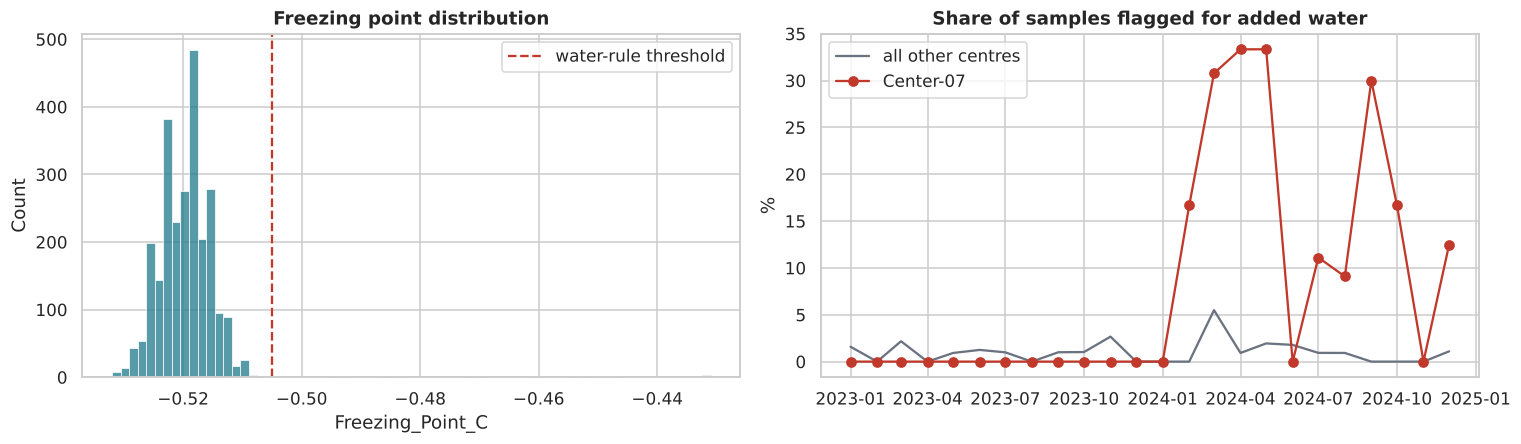

In [10]:
df["Added_Water_pct"] = ((1 - df["Freezing_Point_C"] / FP_REF) * 100)
df["flag_water"] = df["Freezing_Point_C"] > SPEC["fp_max"]
print(f"Water rule (freezing point warmer than {SPEC['fp_max']} C): {int(df['flag_water'].sum())} samples "
      f"({df['flag_water'].mean():.1%}); median estimated added water among them: "
      f"{df.loc[df['flag_water'], 'Added_Water_pct'].median():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(df["Freezing_Point_C"].dropna(), bins=70, color=TEAL, ax=axes[0])
axes[0].axvline(SPEC["fp_max"], color=RED, ls="--", label="water-rule threshold")
axes[0].set_title("Freezing point distribution"); axes[0].legend()

c7 = df["Center"] == "Center-07"
share_c7 = df[c7].groupby("Month")["flag_water"].mean() * 100
share_rest = df[~c7].groupby("Month")["flag_water"].mean() * 100
axes[1].plot(share_rest.index.to_timestamp(), share_rest.values, color=GREY, label="all other centres")
axes[1].plot(share_c7.index.to_timestamp(), share_c7.values, color=RED, marker="o", label="Center-07")
axes[1].set_title("Share of samples flagged for added water"); axes[1].set_ylabel("%"); axes[1].legend()
plt.tight_layout()

pH = 6.95 + (-0.015) x acidity   |   neutralizer rule (robust z > 3.5): 21 samples (0.8%)


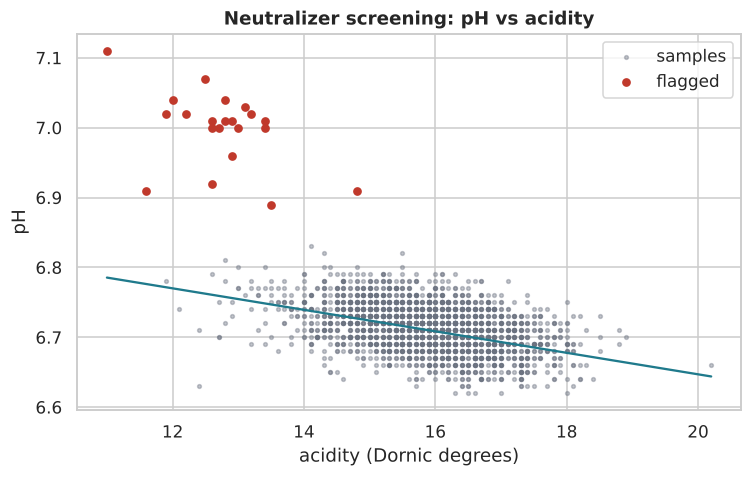

In [11]:
# Neutralizer: pH that is too high for the measured acidity (robust line fitted on all data)
pair = df[["Acidity_Dornic", "pH"]].dropna()
slope, intercept, _, _ = stats.theilslopes(pair["pH"], pair["Acidity_Dornic"])
resid = df["pH"] - (intercept + slope * df["Acidity_Dornic"])
mad = (resid - resid.median()).abs().median()
df["ph_resid_z"] = (resid - resid.median()) / (1.4826 * mad)
df["flag_neut"] = df["ph_resid_z"] > 3.5
print(f"pH = {intercept:.2f} + ({slope:.3f}) x acidity   |   neutralizer rule (robust z > 3.5): "
      f"{int(df['flag_neut'].sum())} samples ({df['flag_neut'].mean():.1%})")

plt.figure(figsize=(7, 4.5))
plt.scatter(df["Acidity_Dornic"], df["pH"], s=6, color=GREY, alpha=0.4, label="samples")
plt.scatter(df.loc[df["flag_neut"], "Acidity_Dornic"], df.loc[df["flag_neut"], "pH"], s=22, color=RED, label="flagged")
xs = np.linspace(df["Acidity_Dornic"].min(), df["Acidity_Dornic"].max(), 50)
plt.plot(xs, intercept + slope * xs, color=TEAL)
plt.xlabel("acidity (Dornic degrees)"); plt.ylabel("pH"); plt.title("Neutralizer screening: pH vs acidity"); plt.legend()
plt.tight_layout()

In [12]:
AD_FEATURES = ["Fat_pct", "Protein_pct", "SNF_pct", "Density_g_ml", "Freezing_Point_C", "Acidity_Dornic", "pH"]
prep = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
Xad = prep.fit_transform(df[AD_FEATURES])
iso = IsolationForest(n_estimators=300, random_state=RANDOM_STATE).fit(Xad)
df["anomaly_score"] = -iso.score_samples(Xad)                 # higher = more unusual
cut = df["anomaly_score"].quantile(0.965)
df["flag_iforest"] = df["anomaly_score"] > cut
df["flag_any"] = df["flag_water"] | df["flag_neut"] | df["flag_iforest"]
print(f"Isolation Forest flags the {df['flag_iforest'].mean():.1%} most unusual samples; any method: {int(df['flag_any'].sum())}")

Isolation Forest flags the 3.5% most unusual samples; any method: 94


### How good is the screening? — with a selection-bias warning

Confirmatory tests exist only for **flagged samples (90% tested) and a random 6% of the rest**. So:

* adulterated samples that *no screening method flagged* are mostly **unlabelled** → recall below is **overestimated**;
* labelled samples are enriched with suspicious ones → precision is **not** the precision in routine operation.

Treat these numbers as an indicative comparison *between methods*, not as production performance. Fixing this needs random confirmatory testing at a known rate.

Also note that this simulation adds **4–18% water**. In reality, small additions (below ~3%) disappear into the natural variation of the freezing point (about ±0.004 °C ≈ ±0.8% water), so a freezing-point rule cannot catch them — one reason real programmes combine several tests.

In [13]:
lab = df[df["Confirmed_Adulterant"].notna()].copy()
is_water_true = lab["Confirmed_Adulterant"] == "Water"
is_neut_true = lab["Confirmed_Adulterant"] == "Neutralizer"
is_any_true = lab["Confirmed_Adulterant"] != "Genuine"
print("Labelled samples:", len(lab), "->", lab["Confirmed_Adulterant"].value_counts().to_dict())

def evaluate(name, flag, truth, target):
    tp = int((flag & truth).sum()); fp = int((flag & ~truth).sum()); fn = int((~flag & truth).sum())
    return {"method": name, "evaluated against": target, "flagged": tp + fp, "caught": tp, "false alarms": fp,
            "missed": fn, "precision": tp / (tp + fp) if (tp + fp) else np.nan,
            "recall": tp / (tp + fn) if (tp + fn) else np.nan}

# each rule is judged against the fraud it is designed to find
pd.DataFrame([
    evaluate("water rule (freezing point)", lab["flag_water"], is_water_true, "water"),
    evaluate("neutralizer rule (pH vs acidity)", lab["flag_neut"], is_neut_true, "neutralizer"),
    evaluate("both rules", lab["flag_water"] | lab["flag_neut"], is_any_true, "any fraud"),
    evaluate("Isolation Forest", lab["flag_iforest"], is_any_true, "any fraud"),
    evaluate("any method", lab["flag_any"], is_any_true, "any fraud"),
]).round(2)

Labelled samples: 272 -> {'Genuine': 214, 'Water': 39, 'Neutralizer': 19}


,method,evaluated against,flagged,caught,false alarms,missed,precision,recall
0,water rule (freezing point),water,38,38,0,1,1.00,0.97
1,neutralizer rule (pH vs acidity),neutralizer,19,19,0,0,1.00,1.00
2,both rules,any fraud,57,57,0,1,1.00,0.98
3,Isolation Forest,any fraud,57,55,2,3,0.96,0.95
4,any method,any fraud,60,58,2,0,0.97,1.00


In [14]:
by_type = lab[is_any_true].groupby("Confirmed_Adulterant").agg(
    confirmed=("flag_any", "size"), water_rule=("flag_water", "sum"), neutralizer_rule=("flag_neut", "sum"),
    isolation_forest=("flag_iforest", "sum"), any_method=("flag_any", "sum"))
print("Confirmed frauds by type, and how many each method caught:")
by_type

Confirmed frauds by type, and how many each method caught:


,confirmed,water_rule,neutralizer_rule,isolation_forest,any_method
Confirmed_Adulterant,,,,,
Neutralizer,19,0,19,17,19
Water,39,38,0,38,39


## 6. Rejections, monitoring and centre scorecards

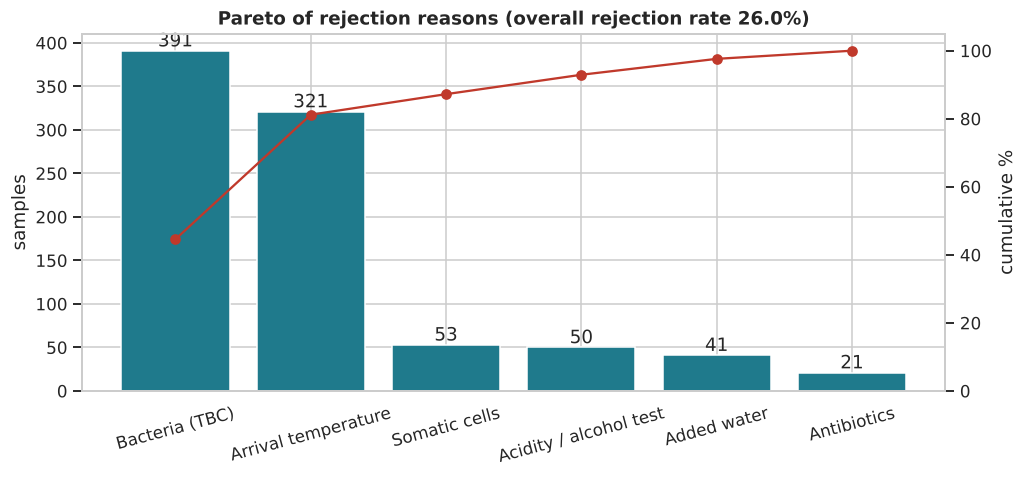

In [15]:
df["r_temp"] = df["Temp_Arrival_C"] > SPEC["temp_max"]
df["r_tbc"] = df["TBC_k"] > SPEC["tbc_max"]
df["r_scc"] = df["SCC_k"] > SPEC["scc_max"]
df["r_antibiotic"] = df["Antibiotic_Test"] == "Positive"
df["r_acid"] = (df["Acidity_Dornic"] > SPEC["acidity_max"]) | (df["Alcohol_Test"] == "Positive")
df["r_water"] = df["flag_water"]

lab_reasons = ["r_tbc", "r_scc", "r_antibiotic", "r_acid", "r_water"]
df["Rejected_Lab"] = df[lab_reasons].any(axis=1).astype(int)
df["Rejected"] = (df["Rejected_Lab"].astype(bool) | df["r_temp"]).astype(int)

nc = pd.Series({"Bacteria (TBC)": df["r_tbc"].sum(), "Arrival temperature": df["r_temp"].sum(),
                "Acidity / alcohol test": df["r_acid"].sum(), "Somatic cells": df["r_scc"].sum(),
                "Added water": df["r_water"].sum(), "Antibiotics": df["r_antibiotic"].sum()}).sort_values(ascending=False)
cum = nc.cumsum() / nc.sum() * 100

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.bar(nc.index, nc.values, color=TEAL)
ax2 = ax.twinx(); ax2.plot(nc.index, cum.values, color=RED, marker="o"); ax2.set_ylim(0, 105); ax2.grid(False); ax2.set_ylabel("cumulative %")
for i, v in enumerate(nc.values):
    ax.text(i, v + 5, int(v), ha="center")
ax.set_title(f"Pareto of rejection reasons (overall rejection rate {df['Rejected'].mean():.1%})")
ax.tick_params(axis="x", rotation=15); ax.set_ylabel("samples")
plt.tight_layout()

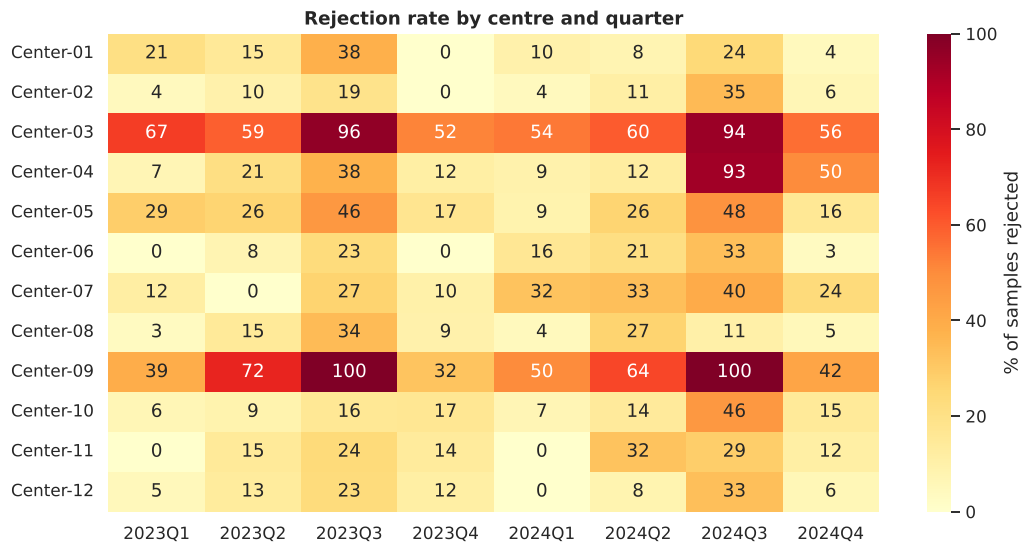

In [16]:
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)
pv = df.pivot_table(index="Center", columns="Quarter", values="Rejected", aggfunc="mean") * 100

plt.figure(figsize=(10, 5.2))
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% of samples rejected"})
plt.title("Rejection rate by centre and quarter"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout()

### Is the overall rejection rate stable? — p-chart

A **p-chart** monitors a proportion. Limits come from the first 12 months (baseline) and widen or narrow with the number of samples each month: p̄ ± 3·√(p̄(1−p̄)/n).

Months outside the limits: ['2023-06', '2023-07', '2023-08', '2023-09', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09']


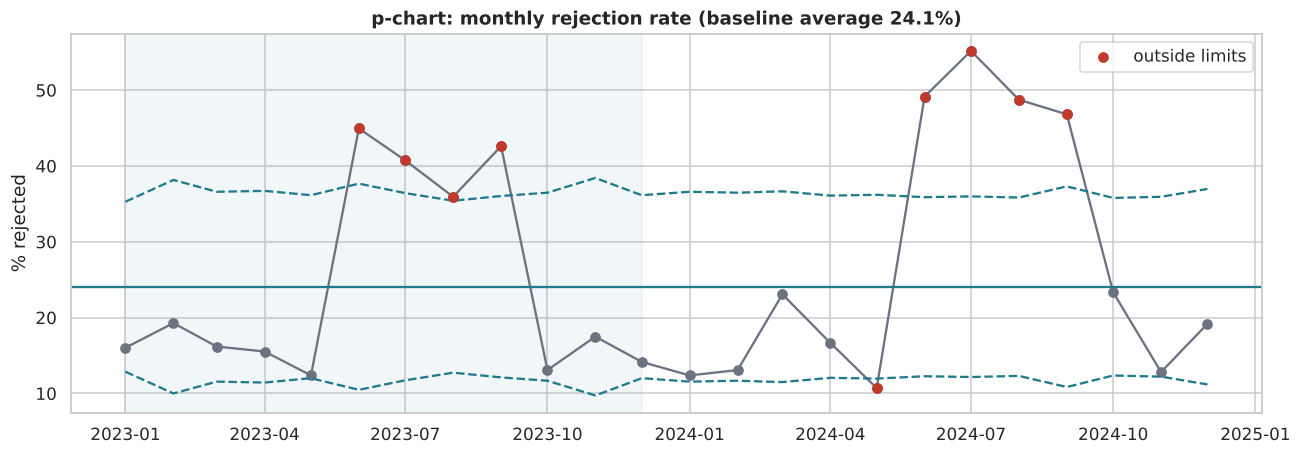

In [17]:
mr = df.groupby("Month").agg(rej=("Rejected", "sum"), n=("Rejected", "size"))
mr["p"] = mr["rej"] / mr["n"]
base = mr.iloc[:12]
pbar = base["rej"].sum() / base["n"].sum()
se = np.sqrt(pbar * (1 - pbar) / mr["n"])
mr["ucl"], mr["lcl"] = pbar + 3 * se, (pbar - 3 * se).clip(lower=0)
mr["signal"] = (mr["p"] > mr["ucl"]) | (mr["p"] < mr["lcl"])

xm = mr.index.to_timestamp()
plt.figure(figsize=(12, 4.3))
plt.plot(xm, mr["p"] * 100, marker="o", color=GREY)
plt.plot(xm, mr["ucl"] * 100, color=TEAL, ls="--"); plt.plot(xm, mr["lcl"] * 100, color=TEAL, ls="--")
plt.axhline(pbar * 100, color=TEAL)
plt.scatter(xm[mr["signal"].to_numpy()], mr.loc[mr["signal"], "p"] * 100, color=RED, zorder=5, label="outside limits")
plt.axvspan(xm[0], xm[11], color=TEAL, alpha=0.06)
plt.title(f"p-chart: monthly rejection rate (baseline average {pbar:.1%})"); plt.ylabel("% rejected"); plt.legend()
plt.tight_layout()
print("Months outside the limits:", [str(m) for m in mr.index[mr["signal"]]])

If signals cluster in the **same calendar months every year**, the process is seasonal rather than out of control — and a seasonal baseline (or a chart per season) is the better tool. Summer is the likely culprit here.

In [18]:
score = df.groupby("Center").agg(samples=("Sample_ID", "size"), reject_pct=("Rejected", "mean"),
                                 scc_mean_k=("SCC_k", "mean"), water_flag_pct=("flag_water", "mean"),
                                 neutralizer_flag_pct=("flag_neut", "mean"))
score["tbc_geo_mean_k"] = df.groupby("Center")["TBC_k"].apply(gmean)
for c in ["reject_pct", "water_flag_pct", "neutralizer_flag_pct"]:
    score[c] = (score[c] * 100).round(1)

def tier(r):                       # illustrative payment / action tiers
    if r["reject_pct"] > 25 or r["water_flag_pct"] > 5 or r["neutralizer_flag_pct"] > 5:
        return "C - corrective action"
    if r["reject_pct"] > 15 or r["water_flag_pct"] > 2 or r["neutralizer_flag_pct"] > 2:
        return "B - watch"
    return "A - approved"
score["tier"] = score.apply(tier, axis=1)
score.sort_values("reject_pct", ascending=False).round(1)

,samples,reject_pct,scc_mean_k,water_flag_pct,neutralizer_flag_pct,tbc_geo_mean_k,tier
Center,,,,,,,
Center-03,218,68.8,290.9,1.4,0.5,472.3,C - corrective action
Center-09,218,61.5,273.8,1.8,0.5,448.9,C - corrective action
Center-04,225,30.2,281.0,0.9,0.0,192.8,C - corrective action
Center-05,212,27.4,514.7,0.9,0.5,160.8,C - corrective action
Center-07,189,23.8,272.2,9.0,0.0,149.1,C - corrective action
Center-01,202,16.8,265.2,1.5,0.0,156.7,B - watch
Center-11,215,16.7,279.3,0.0,7.0,158.9,C - corrective action
Center-10,223,16.1,268.6,1.8,0.9,156.0,B - watch
Center-08,225,13.8,286.2,0.9,0.0,151.9,A - approved


Read the scorecard as a manager would: *which centres need a corrective-action visit, and for what reason?* High TBC with warm arrival points to **cooling**; a high water-flag rate points to **fraud**; a high SCC points to **herd health**.

## 7. Gate-risk model: which tankers deserve priority attention?

**Goal:** rank incoming tankers by risk of a *laboratory* rejection using only information available **at the gate**, so scarce lab capacity goes where it matters most.

**Design choices**
* Inputs: arrival temperature, volume, season, centre — plus **history features**: the centre's rejection rate over its *previous 20* deliveries and its mean log-TBC over the *previous 10*. They use `shift(1)` so a sample never sees its own result (**no leakage**). We assume results of earlier deliveries are known when the next tanker arrives.
* The alcohol test is **excluded**, because it is itself one of the rejection criteria.
* **Time-ordered** split (train on the first 75% of the period) and `TimeSeriesSplit` cross-validation.
* An **ablation** shows what the history features add. They should matter when a centre's behaviour *changes during the period* (for example a cooling tank that fails) — something a fixed centre label cannot know.

In [19]:
dm = df.sort_values(["Date", "Sample_ID"]).reset_index(drop=True).copy()
dm["logTBC"] = np.log10(dm["TBC_k"].clip(lower=1))
g = dm.groupby("Center")
dm["hist_reject_20"] = g["Rejected_Lab"].transform(lambda s: s.shift(1).rolling(20, min_periods=5).mean())
dm["hist_logTBC_10"] = g["logTBC"].transform(lambda s: s.shift(1).rolling(10, min_periods=3).mean())
m = dm["Date"].dt.month
dm["month_sin"], dm["month_cos"] = np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)

CAT = ["Center"]
NUM_BASE = ["Temp_Arrival_C", "Volume_L", "month_sin", "month_cos"]
NUM_HIST = ["hist_reject_20", "hist_logTBC_10"]

cut_i = int(len(dm) * 0.75)
train, test = dm.iloc[:cut_i], dm.iloc[cut_i:]
y_train, y_test = train["Rejected_Lab"], test["Rejected_Lab"]
print(f"train: {len(train)} samples ({train['Date'].min().date()} -> {train['Date'].max().date()}) | "
      f"test: {len(test)} ({test['Date'].min().date()} -> {test['Date'].max().date()})")
print(f"lab-rejection rate  train: {y_train.mean():.1%}   test: {y_test.mean():.1%}")

def make_pipe(model, num_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    prep = ColumnTransformer([("num", num, num_cols), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("model", model)])

models = {"Baseline (prior)": lambda: DummyClassifier(strategy="prior"),
          "Logistic Regression": lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
          "Random Forest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                         random_state=RANDOM_STATE, n_jobs=-1),
          "Hist Gradient Boosting": lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE)}
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for name, mk in models.items():
    r = cross_validate(make_pipe(mk(), NUM_BASE + NUM_HIST), train[CAT + NUM_BASE + NUM_HIST], y_train, cv=tscv,
                       scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    rows.append({"model": name, "PR-AUC": r["test_pr_auc"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
cv_tbl = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
best_name = cv_tbl[cv_tbl["model"] != "Baseline (prior)"].iloc[0]["model"]
print("Time-series CV on the training period (PR-AUC of a useless model = rejection rate = %.3f):" % y_train.mean())
cv_tbl.round(3)

train: 1950 samples (2023-01-01 -> 2024-07-04) | test: 650 (2024-07-05 -> 2024-12-31)
lab-rejection rate  train: 18.1%   test: 24.9%
Time-series CV on the training period (PR-AUC of a useless model = rejection rate = 0.181):


,model,PR-AUC,ROC-AUC
0,Random Forest,0.387,0.716
1,Logistic Regression,0.381,0.680
2,Hist Gradient Boosting,0.310,0.673
3,Baseline (prior),0.187,0.500


In [20]:
def fit_eval(num_cols):
    pipe = make_pipe(models[best_name](), num_cols).fit(train[CAT + num_cols], y_train)
    p = pipe.predict_proba(test[CAT + num_cols])[:, 1]
    return pipe, p, average_precision_score(y_test, p), roc_auc_score(y_test, p)

pipe_base, p_base, pr_base, roc_base = fit_eval(NUM_BASE)
pipe_hist, p_hist, pr_hist, roc_hist = fit_eval(NUM_BASE + NUM_HIST)

ablation = pd.DataFrame({"features": ["gate info only (temperature, volume, season, centre)", "gate info + centre history"],
                         "PR-AUC (test)": [pr_base, pr_hist], "ROC-AUC (test)": [roc_base, roc_hist]})
print(f"Model: {best_name} | useless-model PR-AUC on test = rejection rate = {y_test.mean():.3f}")
gain_pr = pr_hist - pr_base
if gain_pr > 0.02:
    print(f"-> History features raise PR-AUC by {gain_pr:+.3f}: a modest gain, consistent with centres whose behaviour changes "
          f"over time (one test period only, so treat it as indicative).")
else:
    print(f"-> History features change PR-AUC by only {gain_pr:+.3f}: here the centre label and gate measurements already carry most of the signal.")
ablation.round(3)

Model: Random Forest | useless-model PR-AUC on test = rejection rate = 0.249
-> History features raise PR-AUC by +0.027: a modest gain, consistent with centres whose behaviour changes over time (one test period only, so treat it as indicative).


,features,PR-AUC (test),ROC-AUC (test)
0,"gate info only (temperature, volume, season, c...",0.503,0.722
1,gate info + centre history,0.530,0.753


,priority attention to top,rejections anticipated
0,10%,28%
1,20%,44%
2,30%,57%
3,50%,75%


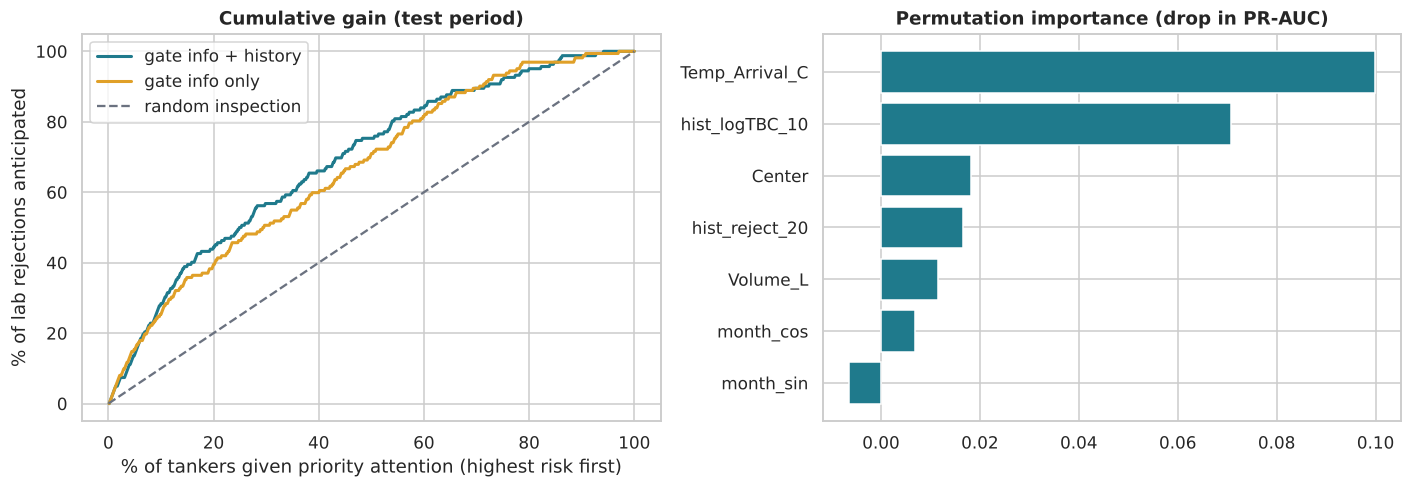

In [21]:
order_idx = np.argsort(-p_hist)
gains = np.cumsum(y_test.to_numpy()[order_idx]) / y_test.sum()
gains_base = np.cumsum(y_test.to_numpy()[np.argsort(-p_base)]) / y_test.sum()
frac = np.arange(1, len(p_hist) + 1) / len(p_hist)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(frac * 100, gains * 100, color=TEAL, lw=2, label="gate info + history")
axes[0].plot(frac * 100, gains_base * 100, color=AMBER, lw=2, label="gate info only")
axes[0].plot([0, 100], [0, 100], "--", color=GREY, label="random inspection")
axes[0].set_xlabel("% of tankers given priority attention (highest risk first)")
axes[0].set_ylabel("% of lab rejections anticipated"); axes[0].set_title("Cumulative gain (test period)"); axes[0].legend()

perm = permutation_importance(pipe_hist, test[CAT + NUM_BASE + NUM_HIST], y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=CAT + NUM_BASE + NUM_HIST).sort_values()
axes[1].barh(imp.index, imp.values, color=TEAL); axes[1].set_title("Permutation importance (drop in PR-AUC)")
plt.tight_layout()

pd.DataFrame({"priority attention to top": ["10%", "20%", "30%", "50%"],
              "rejections anticipated": [f"{gains[int(len(gains) * q) - 1]:.0%}" for q in (0.1, 0.2, 0.3, 0.5)]})

## 8. Summary

In [22]:
print("DATA")
print(f"  raw rows: {len(raw)} -> clean samples: {len(df)}")
print(f"  overall rejection rate: {df['Rejected'].mean():.1%} (lab reasons only: {df['Rejected_Lab'].mean():.1%})")
print("\nADULTERATION SCREENING")
print(f"  samples flagged for added water: {int(df['flag_water'].sum())} "
      f"(Center-07 share of them: {df.loc[df['flag_water'], 'Center'].eq('Center-07').mean():.0%})")
print(f"  samples flagged by the neutralizer rule: {int(df['flag_neut'].sum())} "
      f"(Center-11 share: {df.loc[df['flag_neut'], 'Center'].eq('Center-11').mean():.0%})")
print("\nCENTRES")
print("  tiers:", score["tier"].value_counts().to_dict())
print("  worst by rejection rate:", score["reject_pct"].sort_values(ascending=False).head(3).to_dict())
print("\nGATE-RISK MODEL (time-ordered test period)")
print(f"  {best_name}: PR-AUC {pr_hist:.2f} with history vs {pr_base:.2f} without (useless model: {y_test.mean():.2f})")
print(f"  prioritising the top 20% of tankers anticipates {gains[int(len(gains) * 0.2) - 1]:.0%} of lab rejections")

DATA
  raw rows: 2631 -> clean samples: 2600
  overall rejection rate: 26.0% (lab reasons only: 19.8%)

ADULTERATION SCREENING
  samples flagged for added water: 41 (Center-07 share of them: 41%)
  samples flagged by the neutralizer rule: 21 (Center-11 share: 71%)

CENTRES
  tiers: {'C - corrective action': 6, 'A - approved': 4, 'B - watch': 2}
  worst by rejection rate: {'Center-03': 68.8, 'Center-09': 61.5, 'Center-04': 30.2}

GATE-RISK MODEL (time-ordered test period)
  Random Forest: PR-AUC 0.53 with history vs 0.50 without (useless model: 0.25)
  prioritising the top 20% of tankers anticipates 44% of lab rejections


### Limitations and next steps
* **Simulated data.** The notebook shows a *workflow*; the findings describe a simulated process whose events were built in. Re-run on an anonymised export of your own plant before drawing conclusions.
* **Rejection rates here (about 20-26%) are far higher than a healthy milk supply chain, where a few percent is typical.** They were set high on purpose so that every analysis has enough events to work with.
* Limits (TBC, SCC, freezing point, temperature) are **illustrative** — use your national standard or supplier contract.
* The freezing-point reference (−0.520 °C) varies by region and season; establish your own baseline per centre.
* Adulteration evaluation is biased by how confirmatory tests were chosen; **randomised confirmatory testing** at a known rate would fix that.
* Ideas to extend: EWMA / CUSUM charts per centre, change-point detection for the start of a fraud, payment formulas based on composition and hygiene, and a small Streamlit app for gate staff.